# Peak-density zoom — pyablo-free pipeline

Full workflow using only h5py + numba:

1. Read metadata from config (no pyablo)
2. Stream full box at base resolution → find peak density
3. Stream only the sub-cube around the peak (two fields: `rho`, `rho_HII`)
4. Project both fields at lcube = 8, 9, 10 with `numba_full` in a single pass
5. Visualise: full-box overview + zoom panels for each field and resolution

**Run from `multiamr2cube_optim/`.**

In [1]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import time

BASE_DIR   = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'claude' else os.getcwd()
CLAUDE_DIR = os.path.join(BASE_DIR, 'claude')
sys.path.insert(0, CLAUDE_DIR)

from load_subcube_h5py       import load_subcube, metadata_from_config
import multiamr2cube_numba_full as m
from multiamr2cube_numba_full import cell_coords

# --- paths (edit if needed) ---
H5PATH  = os.path.join(BASE_DIR, 'star_iter0070000.h5')
CFGPATH = os.path.join(BASE_DIR, 'restart_star_279982.ini')
FIELDS  = ['rho', 'rho_HII']

print('h5 :', H5PATH)
print('cfg:', CFGPATH)

h5 : /Users/pedro/work/simus/dyablo/dyablo/multiamr2cube_optim/star_iter0070000.h5
cfg: /Users/pedro/work/simus/dyablo/dyablo/multiamr2cube_optim/restart_star_279982.ini


## 1 — Metadata from config

In [2]:
Lbox, bx = metadata_from_config(CFGPATH)
print('Lbox =', Lbox)
print('bx   =', bx)

Lbox = [1.84219576e+23 1.84219576e+23 1.84219576e+23]
bx   = 4


## 2 — Stream full box → find peak density

Pass 1 scans the full connectivity (~3 s); pass 2 reads only the rho field.
We then project at the base resolution (lcube = lmin) to locate the peak.

In [3]:
t0 = time.perf_counter()
cc_full, lcell_full, fields_full = load_subcube(
    H5PATH, fieldnames=['rho'], lcube=8,
    Lbox=Lbox, bx=bx, extent=[0,1,0,1,0,1],
)
t_load_full = time.perf_counter() - t0

rho_full = fields_full['rho']
lmin = int(lcell_full.min())
lmax = int(lcell_full.max())
print('Loaded %d cells in %.1fs | lmin=%d lmax=%d' % (len(rho_full), t_load_full, lmin, lmax))

Snapshot: 27,825,344 cells | raw levels 6-8 | lcell 8-10
Pass 1: scanning 56 chunks of 500,000 cells ...
    1.8%  chunk 1/56  kept so far: 500,000
   10.7%  chunk 6/56  kept so far: 3,000,000
   19.6%  chunk 11/56  kept so far: 5,500,000
   28.6%  chunk 16/56  kept so far: 8,000,000
   37.5%  chunk 21/56  kept so far: 10,500,000
   46.4%  chunk 26/56  kept so far: 13,000,000
   55.4%  chunk 31/56  kept so far: 15,500,000
   64.3%  chunk 36/56  kept so far: 18,000,000
   73.2%  chunk 41/56  kept so far: 20,500,000
   82.1%  chunk 46/56  kept so far: 23,000,000
   91.1%  chunk 51/56  kept so far: 25,500,000
  100.0%  chunk 56/56  kept so far: 27,825,344

Pass 1 done: 27,825,344 cells kept (100.0% of total) in 1 contiguous run(s)
Pass 2: reading 1 field(s) across 1 range(s) ...
Done.
Loaded 27825344 cells in 3.2s | lmin=8 lmax=10


In [4]:
# warm up numba on a tiny slice before timing
m.warmup(cc_full, lcell_full, rho_full, Lbox)

t0 = time.perf_counter()
cube_full = m.multiamr2cube(cc_full, lcell_full, rho_full, Lbox, lcube=lmin)
t_proj_full = time.perf_counter() - t0

x_full, y_full, z_full = cell_coords(lmin, extent=[0, 1, 0, 1, 0, 1])

print('Full-box grid shape:', cube_full.shape)
print('Projection time: %.3fs' % t_proj_full)
print('dx = %.6f  (full box)' % (x_full[1] - x_full[0]))

Full-box grid shape: (256, 256, 256)
Projection time: 0.283s
dx = 0.003906  (full box)


## 3 — Locate peak and define sub-cube extent

In [5]:
# Find the peak in the raw cell data — not the projected grid.
# At lcube=lmin the true peak cell (finest level) can be overwritten
# by its neighbours ("last write wins"), so argmax on the cube is wrong.
peak_idx = np.argmax(rho_full)
peak_cc  = cc_full[peak_idx]               # physical coordinates
peak_frac = peak_cc / np.array(Lbox)       # fractional coordinates in [0,1]

print('Peak cell index : %d' % peak_idx)
print('Peak rho        : %.4e' % rho_full[peak_idx])
print('Peak lcell      : %d'   % lcell_full[peak_idx])
print('Peak frac       : (%.4f, %.4f, %.4f)' % tuple(peak_frac))

# sub-cube: 0.1 x box side centred on peak, clipped to [0, 1]
hw = 0.05
EXTENT = [
    max(0.0, peak_frac[0] - hw), min(1.0, peak_frac[0] + hw),
    max(0.0, peak_frac[1] - hw), min(1.0, peak_frac[1] + hw),
    max(0.0, peak_frac[2] - hw), min(1.0, peak_frac[2] + hw),
]
print('Sub-cube extent : [%.4f, %.4f, %.4f, %.4f, %.4f, %.4f]' % tuple(EXTENT))

Peak cell index : 13980679
Peak rho        : 1.7777e-22
Peak lcell      : 10
Peak frac       : (0.2183, 0.0757, 0.6724)
Sub-cube extent : [0.1683, 0.2683, 0.0257, 0.1257, 0.6224, 0.7224]


## 4 — Stream only the sub-cube (both fields in one pass)

In [6]:
t0 = time.perf_counter()
cc, lcell, fields = load_subcube(
    H5PATH, fieldnames=FIELDS, lcube=10,
    Lbox=Lbox, bx=bx, extent=EXTENT,
)
t_load_sub = time.perf_counter() - t0

rho    = fields['rho']
rhoHII = fields['rho_HII']
print('Sub-cube: %d cells loaded in %.1fs' % (len(rho), t_load_sub))
print('Fraction of full box: %.1f%%' % (100.0 * len(rho) / len(rho_full)))

# Stack fields into (Nc, Nfields) for the multi-field kernel
values = np.stack([rho, rhoHII], axis=-1)
print('values shape:', values.shape, '  (Nc, Nfields)')

Snapshot: 27,825,344 cells | raw levels 6-8 | lcell 8-10
Pass 1: scanning 56 chunks of 500,000 cells ...
    1.8%  chunk 1/56  kept so far: 0
   10.7%  chunk 6/56  kept so far: 0
   19.6%  chunk 11/56  kept so far: 0
   28.6%  chunk 16/56  kept so far: 0
   37.5%  chunk 21/56  kept so far: 0
   46.4%  chunk 26/56  kept so far: 0
   55.4%  chunk 31/56  kept so far: 282,379
   64.3%  chunk 36/56  kept so far: 282,379
   73.2%  chunk 41/56  kept so far: 282,379
   82.1%  chunk 46/56  kept so far: 282,379
   91.1%  chunk 51/56  kept so far: 282,379
  100.0%  chunk 56/56  kept so far: 282,379

Pass 1 done: 282,379 cells kept (1.0% of total) in 5446 contiguous run(s)
Pass 2: reading 2 field(s) across 5446 range(s) ...
Done.
Sub-cube: 282379 cells loaded in 2.9s
Fraction of full box: 1.0%
values shape: (282379, 2)   (Nc, Nfields)


## 5 — Project both fields at lcube = 8, 9, 10 (single pass each)

In [7]:
LCUBES = [8, 10, 12]
cubes  = {}   # cubes[lcube] -> (nx, ny, nz, 2)  last axis: [rho, rho_HII]
coords = {}   # coords[lcube] -> (x, y, z)  1-D arrays of cell centres in [0,1]
times  = {}

# warm up for the 2-field specialisation
m.warmup(cc, lcell, values, Lbox)

for lcube in LCUBES:
    t0 = time.perf_counter()
    cubes[lcube] = m.multiamr2cube(cc, lcell, values, Lbox, lcube=lcube, extent=EXTENT)
    times[lcube] = time.perf_counter() - t0
    coords[lcube] = cell_coords(lcube, extent=EXTENT)
    x, y, z = coords[lcube]
    print('lcube=%d  grid=%-20s  %.3fs  x=[%.4f..%.4f]  dx=%.6f' % (
        lcube, str(cubes[lcube].shape), times[lcube],
        x[0], x[-1], x[1] - x[0]))

lcube=8  grid=(26, 26, 26, 2)       0.001s  x=[0.1699..0.2676]  dx=0.003906
lcube=10  grid=(102, 102, 102, 2)    0.026s  x=[0.1685..0.2671]  dx=0.000977
lcube=12  grid=(410, 410, 410, 2)    1.524s  x=[0.1683..0.2682]  dx=0.000244


## 6 — Visualisation

**Top row:** full-box rho overview (max-z projection) + zoom at lcube = 8, 9, 10.  
**Bottom row:** ionised fraction xHII = rho_HII / rho zoom at lcube = 8, 9, 10.

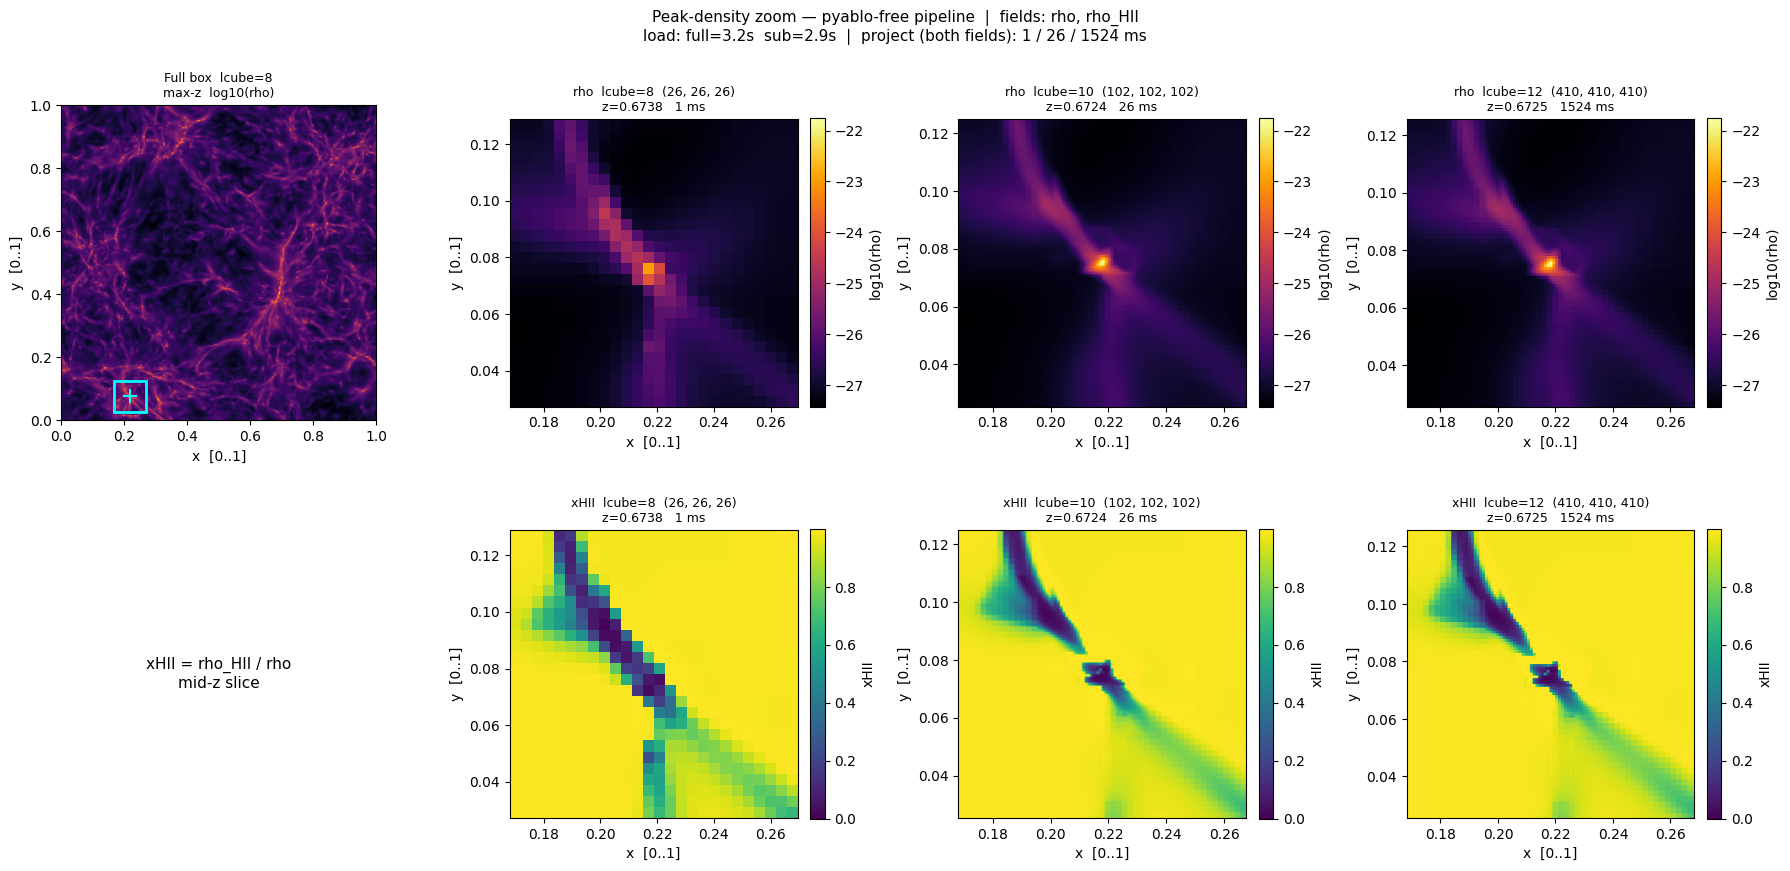

Saved /Users/pedro/work/simus/dyablo/dyablo/multiamr2cube_optim/claude/demo_peak_zoom.png


In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# ---- shared colour scales ----
rho_slices = [np.log10(cubes[lc][:, :, cubes[lc].shape[2]//2, 0] + 1e-30) for lc in LCUBES]
rho_vmin = min(s.min() for s in rho_slices)
rho_vmax = max(s.max() for s in rho_slices)

xHII_slices = [
    cubes[lc][:, :, cubes[lc].shape[2]//2, 1]
    / np.clip(cubes[lc][:, :, cubes[lc].shape[2]//2, 0], 1e-30, None)
    for lc in LCUBES
]
xHII_vmin = 0.0
xHII_vmax = max(s.max() for s in xHII_slices)

def imshow_extent(x, y):
    """Pixel-edge extent for imshow from cell-centre coordinate arrays."""
    dx = x[1] - x[0]
    dy = y[1] - y[0]
    return [x[0] - dx/2, x[-1] + dx/2, y[0] - dy/2, y[-1] + dy/2]

# ---- row 0 col 0: full-box rho overview ----
ax0 = axes[0, 0]
ov  = np.log10(cube_full.max(axis=2) + 1e-30)
ax0.imshow(ov.T, origin='lower', aspect='equal', cmap='inferno',
           extent=imshow_extent(x_full, y_full),
           vmin=ov.min(), vmax=ov.max())
rect = mpatches.Rectangle(
    (EXTENT[0], EXTENT[2]),
    EXTENT[1] - EXTENT[0], EXTENT[3] - EXTENT[2],
    linewidth=2, edgecolor='cyan', facecolor='none',
)
ax0.add_patch(rect)
ax0.plot(peak_frac[0], peak_frac[1], '+', color='cyan', markersize=10, markeredgewidth=1.5)
ax0.set_title('Full box  lcube=%d\nmax-z  log10(rho)' % lmin, fontsize=9)
ax0.set_xlabel('x  [0..1]'); ax0.set_ylabel('y  [0..1]')

# ---- row 1 col 0: empty / label ----
axes[1, 0].axis('off')
axes[1, 0].text(0.5, 0.5,
    'xHII = rho_HII / rho\nmid-z slice',
    ha='center', va='center', fontsize=11, transform=axes[1, 0].transAxes)

# ---- zoom panels ----
for col, lcube in enumerate(LCUBES):
    arr        = cubes[lcube]           # (nx, ny, nz, 2)
    x, y, z    = coords[lcube]
    mid        = arr.shape[2] // 2
    ext        = imshow_extent(x, y)
    z_mid      = z[mid]                 # physical z of the slice
    rho_s      = arr[:, :, mid, 0]
    hii_s      = arr[:, :, mid, 1]

    # row 0: log rho
    ax = axes[0, col + 1]
    sl = np.log10(rho_s + 1e-30)
    im = ax.imshow(sl.T, origin='lower', aspect='equal', cmap='inferno',
                   extent=ext, vmin=rho_vmin, vmax=rho_vmax)
    ax.set_title('rho  lcube=%d  %s\nz=%.4f   %.0f ms' % (
                 lcube, str(arr.shape[:3]), z_mid, times[lcube]*1e3), fontsize=9)
    ax.set_xlabel('x  [0..1]'); ax.set_ylabel('y  [0..1]')
    plt.colorbar(im, ax=ax, label='log10(rho)', fraction=0.046, pad=0.04)

    # row 1: ionised fraction
    ax = axes[1, col + 1]
    xHII = hii_s / np.clip(rho_s, 1e-30, None)
    im = ax.imshow(xHII.T, origin='lower', aspect='equal', cmap='viridis',
                   extent=ext, vmin=xHII_vmin, vmax=xHII_vmax)
    ax.set_title('xHII  lcube=%d  %s\nz=%.4f   %.0f ms' % (
                 lcube, str(arr.shape[:3]), z_mid, times[lcube]*1e3), fontsize=9)
    ax.set_xlabel('x  [0..1]'); ax.set_ylabel('y  [0..1]')
    plt.colorbar(im, ax=ax, label='xHII', fraction=0.046, pad=0.04)

fig.suptitle(
    'Peak-density zoom — pyablo-free pipeline  |  fields: %s\n'
    'load: full=%.1fs  sub=%.1fs  |  project (both fields): %s ms' % (
        ', '.join(FIELDS),
        t_load_full, t_load_sub,
        ' / '.join(['%.0f' % (times[lc]*1e3) for lc in LCUBES])
    ),
    fontsize=11,
)

plt.tight_layout()
outpath = os.path.join(CLAUDE_DIR, 'demo_peak_zoom.png')
plt.savefig(outpath, dpi=150, bbox_inches='tight')
plt.show()
print('Saved', outpath)